In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging

from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import matplotlib.pyplot as plt

from models.train_model import get_model
from utils.plotting import plot_single_valuation
from utils.evaluation import evaluate_model

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [9]:
DATASET_NAME = "wine"
MODEL_NAME = "logistic"
SCORING = "accuracy"
METHODS = "anova"

RANDOM_STATE = 42

OUTPUT_DIR = Path(f"./output/feature_valuation/{DATASET_NAME}_{MODEL_NAME}_{SCORING}_{METHODS}_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [10]:
def load_dataset(name: str):
    path_map = {
        "breast_cancer": "datasets/breast_cancer/breast_cancer_preprocessed.npz",
        "congress": "../datasets/congress/congress_preprocessed.npz",
        "wine": "../datasets/wine/wine_preprocessed.npz",
        "apple_quality": "../datasets/apple_quality/apple_quality_preprocessed_no_scaling.npz",
        "yield_synthetic": "../datasets/yield_synthetic/yield_preprocessed.npz"
    }
    path = Path(path_map[name])
    data = np.load(path, allow_pickle=True)
    feature_names = data["feature_names"].tolist() if "feature_names" in data else [f"f{i}" for i in range(data["X_train"].shape[1])]
    return data["X_train"], data["X_test"], data["y_train"], data["y_test"], feature_names

In [11]:
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

In [12]:
X_train, X_test, y_train, y_test, feature_names = load_dataset(DATASET_NAME)
scorer = get_scorer(SCORING)

In [13]:
from sklearn.feature_selection import f_classif, f_regression

# Determine if classification or regression
is_classification = len(np.unique(y_train)) <= 10  # Heuristic

if is_classification:
    print("Using ANOVA F-test for classification (f_classif)")
    f_scores, p_values = f_classif(X_train, y_train)
else:
    print("Using ANOVA F-test for regression (f_regression)")
    f_scores, p_values = f_regression(X_train, y_train)

print(f"\nANOVA F-scores:")
for fname, f_score, p_val in zip(feature_names, f_scores, p_values):
    print(f"  {fname}: F={f_score:.4f}, p-value={p_val:.4e}")

Using ANOVA F-test for classification (f_classif)

ANOVA F-scores:
  Alcohol: F=106.3378, p-value=1.1302e-28
  Malic acid: F=34.7551, p-value=5.9696e-13
  Ash: F=12.8558, p-value=7.5887e-06
  Alcalinity of ash: F=25.5641, p-value=3.5931e-10
  Magnesium: F=8.8349, p-value=2.4522e-04
  Total phenols: F=76.9424, p-value=3.5650e-23
  Flavanoids: F=236.4193, p-value=2.6469e-45
  Nonflavanoid phenols: F=19.9312, p-value=2.4879e-08
  Proanthocyanins: F=23.4032, p-value=1.7708e-09
  Color intensity: F=100.6359, p-value=1.1063e-27
  Hue: F=82.6452, p-value=2.5317e-24
  OD280/OD315 of diluted wines: F=141.7945, p-value=3.4222e-34
  Proline: F=175.2992, p-value=1.3001e-38


In [14]:
anova_importance = f_scores

results = {
    "anova": anova_importance
}

df = pd.DataFrame([
    {"method": "anova", "feature": feature_names[i], "value": v}
    for i, v in enumerate(anova_importance)
])

print("\nANOVA Results DataFrame:")
print(df.sort_values("value", ascending=False))

# Save to CSV
df.to_csv(OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_anova_valuations.csv", index=False)
print(f"\nResults saved to: {OUTPUT_DIR / f'{DATASET_NAME}_{MODEL_NAME}_anova_valuations.csv'}")


ANOVA Results DataFrame:
   method                       feature       value
6   anova                    Flavanoids  236.419286
12  anova                       Proline  175.299157
11  anova  OD280/OD315 of diluted wines  141.794451
0   anova                       Alcohol  106.337842
9   anova               Color intensity  100.635855
10  anova                           Hue   82.645226
5   anova                 Total phenols   76.942437
1   anova                    Malic acid   34.755071
3   anova             Alcalinity of ash   25.564108
8   anova               Proanthocyanins   23.403225
7   anova          Nonflavanoid phenols   19.931231
2   anova                           Ash   12.855823
4   anova                     Magnesium    8.834910

Results saved to: output/feature_valuation/wine_logistic_accuracy_anova_results/wine_logistic_anova_valuations.csv



Plot saved!


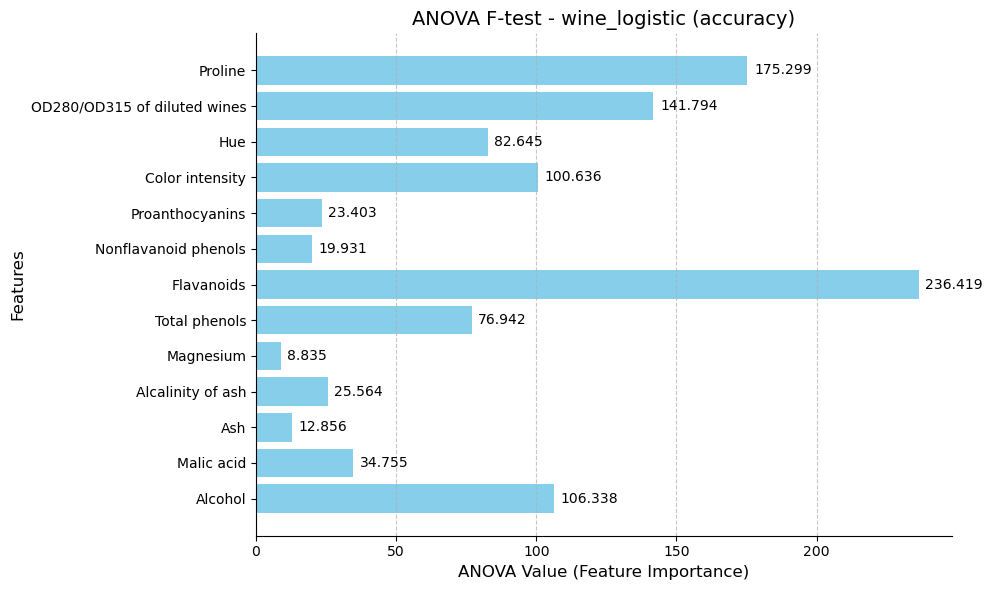

In [15]:
plot_single_valuation(
    anova_importance,
    feature_names,
    method_name="ANOVA",
    title=f"ANOVA F-test - {DATASET_NAME}_{MODEL_NAME} ({SCORING})",
    output_path=OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_anova_{SCORING}.png"
)

print(f"\nPlot saved!")

In [9]:
model = get_model(MODEL_NAME, RANDOM_STATE)
model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [10]:
print(f"Dataset: {DATASET_NAME}")
print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"Features: {feature_names}")
print(f"Model trained: {type(model).__name__}")

Dataset: yield_synthetic
Train shape: (800, 4)
Test shape: (200, 4)
Features: ['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']
Model trained: Pipeline


In [11]:
from lime.lime_tabular import LimeTabularExplainer

unique_classes = np.unique(y_train)
n_classes = len(unique_classes)

print(f"Number of classes: {n_classes}")
print(f"Class labels: {unique_classes}")

Number of classes: 3
Class labels: [0 1 2]


In [9]:
ground_truth = pd.Series({
    "Nitrogen": 2.764945,
    "Irrigation": 3.706509,
    "Precipitation": 2.052278,
    "Herbicide": 0.817947
}, name="GroundTruth")

gt_norm = ground_truth / ground_truth.sum()

In [10]:
gt_norm

Nitrogen         0.295979
Irrigation       0.396771
Precipitation    0.219690
Herbicide        0.087559
Name: GroundTruth, dtype: float64

In [11]:
anova_subset = df[df["method"] == "anova"].set_index("feature")["value"]
anova_norm = anova_subset / anova_subset.sum()

# Align with ground truth index
anova_norm = anova_norm[gt_norm.index]

In [12]:
df_val = pd.DataFrame([
    {"method": "anova", "feature": feature_names[i], "value": v}
    for i, v in enumerate(anova_norm)
])

print("\nDataFrame created:")
print(df_val)


DataFrame created:
  method        feature     value
0  anova       Nitrogen  0.068723
1  anova     Irrigation  0.744667
2  anova  Precipitation  0.183672
3  anova      Herbicide  0.002938



Comparison with Ground Truth 
  method  Spearman   Pearson  CosineSim      MAPE
0  anova       0.8  0.804862   0.843665  0.693756


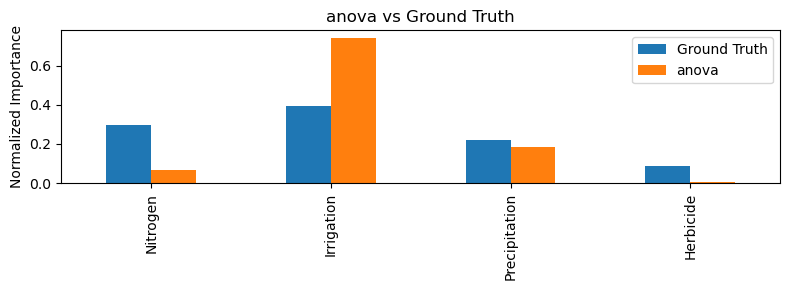

In [13]:
results = []

for method in df_val["method"].unique():
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]

    subset_norm = subset / subset.sum()

    subset_norm = subset_norm[gt_norm.index]

    spearman_corr, _ = spearmanr(gt_norm, subset_norm)
    pearson_corr, _ = pearsonr(gt_norm, subset_norm)
    cos_sim = np.dot(gt_norm, subset_norm) / (norm(gt_norm) * norm(subset_norm))
    mape = (abs(gt_norm - subset_norm) / gt_norm).mean()

    results.append({
        "method": method,
        "Spearman": spearman_corr,
        "Pearson": pearson_corr,
        "CosineSim": cos_sim,
        "MAPE": mape
    })


results_df = pd.DataFrame(results).sort_values("CosineSim", ascending=False)
print("\nComparison with Ground Truth ")
print(results_df)


methods_to_plot = df_val["method"].unique()

fig, axes = plt.subplots(len(methods_to_plot), 1, figsize=(8, 3*len(methods_to_plot)))
if len(methods_to_plot) == 1:
    axes = [axes]

for ax, method in zip(axes, methods_to_plot):
    subset = df_val[df_val["method"] == method].set_index("feature")["value"]
    subset_norm = subset / subset.sum()
    subset_norm = subset_norm[gt_norm.index]

    pd.DataFrame({
        "Ground Truth": gt_norm,
        method: subset_norm
    }).plot(kind='bar', ax=ax)

    ax.set_title(f"{method} vs Ground Truth")
    ax.set_ylabel("Normalized Importance")

plt.tight_layout()
plt.show()